In [1]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.integrate import solve_ivp
#lorentz's parameters (chaotic)
sigma = 10
beta = 8/3
rho = 28

In [7]:
#integrator
def rk4singlestep(fun, dt, t0, y0):
    f1 = fun(t0, y0)
    f2 = fun(t0+ dt/2, y0 + (dt/2)*f1)
    f3 = fun(t0+dt/2, y0+(dt/2)*f2)
    f4 = fun(t0+dt, y0+dt*f3)
    yout = y0+(dt/6)*(f1+2*f2+2*f3+f4)
    return yout

In [8]:
def lorenz(t, y):
    #y is a three dimensional state-vector
    dy = [sigma*(y[1] - y[0]), y[0] * (rho-y[2]) - y[1], (y[0]*y[1])- beta*y[2]]
    return np.array(dy)


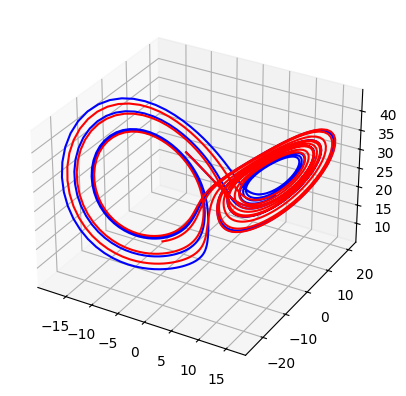

In [11]:
# initial condition
y0 = [-8, 8, 27]
#compute trajectory
dt = 0.01
T = 10
num_time_pts = int(T/dt)
t= np.linspace(0, T, num_time_pts)

Y = np.zeros((3, num_time_pts))
Y[:, 0] = y0
yin = y0
for i in range(num_time_pts - 1):
    yout = rk4singlestep(lorenz, dt, t[i], yin)
    Y[:,i+1] = yout
    yin = yout

ax = plt.figure().add_subplot(projection = '3d')
ax.plot(Y[0,:], Y[1, :], Y[2, :], 'b')
lorenz_solution = solve_ivp(lorenz, (0, T), y0, t_eval = t)
t = lorenz_solution.t
y = lorenz_solution.y.T
ax.plot(y[:,0], y[:, 1], y[:, 2], 'r')
plt.show()